In [11]:
%matplotlib inline
import matplotlib
import matplotlib.pyplot as plt
from script_read_normalise_pseudoecgv3 import *

In [ ]:
filtering = True
normalise = True
zero_align = True
frequency = 1000
high_freq_cut = 150
low_freq_cut = 0.5
max_len_ecg = 500
qrs_window_ms = 150.0
nb_leads = 12
qrs_onset = 0
scaling_mode = 'two_groups' # 'global', 'two_groups', 'per_lead'
sim_folder = os.path.join(".", "sb3901","test_mono_torord_sb3901_LBBB_fast4x_prep0")
casename = 'sb3901'
sim_ecg_igb_filename = casename + '_phie_recovery.igb'
sim_ecg_igb_path = os.path.join(sim_folder, sim_ecg_igb_filename)
sim_ecg_filename = casename + '_phierec_ascii_LBBB.txt'
sim_ecg_path = os.path.join(sim_folder, sim_ecg_filename)
ptb_casename = "patient208"               #"patient131"             #
ptb_filename = "s0429_re"                  # "s0273lre" 
ptb_record_path=os.path.join('..', '..','ptb-diagnostic-ecg-database-1.0.0', "LBBB",ptb_casename, ptb_filename)  # Path SENZA estensione, es. './ptb_ecg_records/s0010_re'
ptb_target_len_ms = 500.0
ptb_qrs_pre_ms = 120.0

# Read in simulated ECGs
print('Importing and preprocessing simulated ECG')
cmd_convert_igb_txt =[
    'opencarp-docker',
    'igbextract', '-l', "0-9", "-o","asciiTm", "-O",
    sim_ecg_path,
    sim_ecg_igb_path
] 
print("Running command:", " ".join(cmd_convert_igb_txt))
subprocess.run(cmd_convert_igb_txt, check=True)

simulated_t_ms, simulated_ecgs_12leads = import_simulated_ecg_12leads_raw(filename=sim_ecg_path, monoalg_activation_offset=0)
#simulation_frequency = simulated_ecgs_12leads.shape[1]
sim_freq = 1000.0 / np.mean(np.diff(simulated_t_ms)) if len(simulated_t_ms) > 1 else 1000.0

print('simulated_ecgs_12leads.shape ', simulated_ecgs_12leads.shape)
print('simulation_frequency ', sim_freq)
#max_len_qrs = 200 * 4

print('Importing PTB ECG with wfdb...')
reference_t_ms_full, reference_ecg_12_full, reference_fs, reference_sig_names = import_ptb_ecg_12leads(ptb_record_path)
print(f'PTB ECG shape: {reference_ecg_12_full.shape}, fs = {reference_fs:.2f} Hz')
print('Available PTB signals:', reference_sig_names)
# Plot together
print('Visualising ECGs together')


Importing and preprocessing simulated ECG
Running command: opencarp-docker igbextract -l 0-9 -o asciiTm -O ./sb4301/test_mono_torord_sb4301_LBBB_CVcampsv2_fast4x_grad10abtm_purkinje300_prep0/sb4301_phierec_ascii_LBBB.txt ./sb4301/test_mono_torord_sb4301_LBBB_CVcampsv2_fast4x_grad10abtm_purkinje300_prep0/sb4301_phie_recovery.igb
Start running docker...
simulated_ecgs_12leads.shape  (12, 500)
simulation_frequency  1000.0
Importing PTB ECG with wfdb...
PTB ECG shape: (12, 91987), fs = 1000.00 Hz
Available PTB signals: ['I', 'II', 'III', 'aVR', 'aVL', 'aVF', 'V1', 'V2', 'V3', 'V4', 'V5', 'V6', 'VX', 'VY', 'VZ']
Visualising ECGs together


Numero di picchi R trovati nel PTB: 104
Picco centrale selezionato al campione: 46011
Beat PTB estratto shape: (12, 500)

=== Scaling report ===
Mode: two_groups
 I | ref_amp= 0.6382 mV | sim_amp= 0.0452 mV | scale= 24.6424
II | ref_amp= 0.8753 mV | sim_amp=-0.0162 mV | scale= 24.6424
III | ref_amp=-0.8371 mV | sim_amp=-0.0493 mV | scale= 24.6424
aVR | ref_amp=-0.6967 mV | sim_amp=-0.0225 mV | scale= 24.6424
aVL | ref_amp= 0.6919 mV | sim_amp= 0.0462 mV | scale= 24.6424
aVF | ref_amp= 0.6222 mV | sim_amp=-0.0291 mV | scale= 24.6424
V1 | ref_amp=-2.6770 mV | sim_amp=-0.3098 mV | scale= 7.9003
V2 | ref_amp=-4.1954 mV | sim_amp=-0.5176 mV | scale= 7.9003
V3 | ref_amp=-3.4268 mV | sim_amp=-0.4217 mV | scale= 7.9003
V4 | ref_amp=-1.5991 mV | sim_amp=-0.2899 mV | scale= 7.9003
V5 | ref_amp= 1.5258 mV | sim_amp= 0.1802 mV | scale= 7.9003
V6 | ref_amp= 1.4409 mV | sim_amp= 0.1624 mV | scale= 7.9003
Saved clinical beat 12 leads CSV: ./sb4301/test_mono_torord_sb4301_LBBB_CVcampsv2_fast4x_grad10a

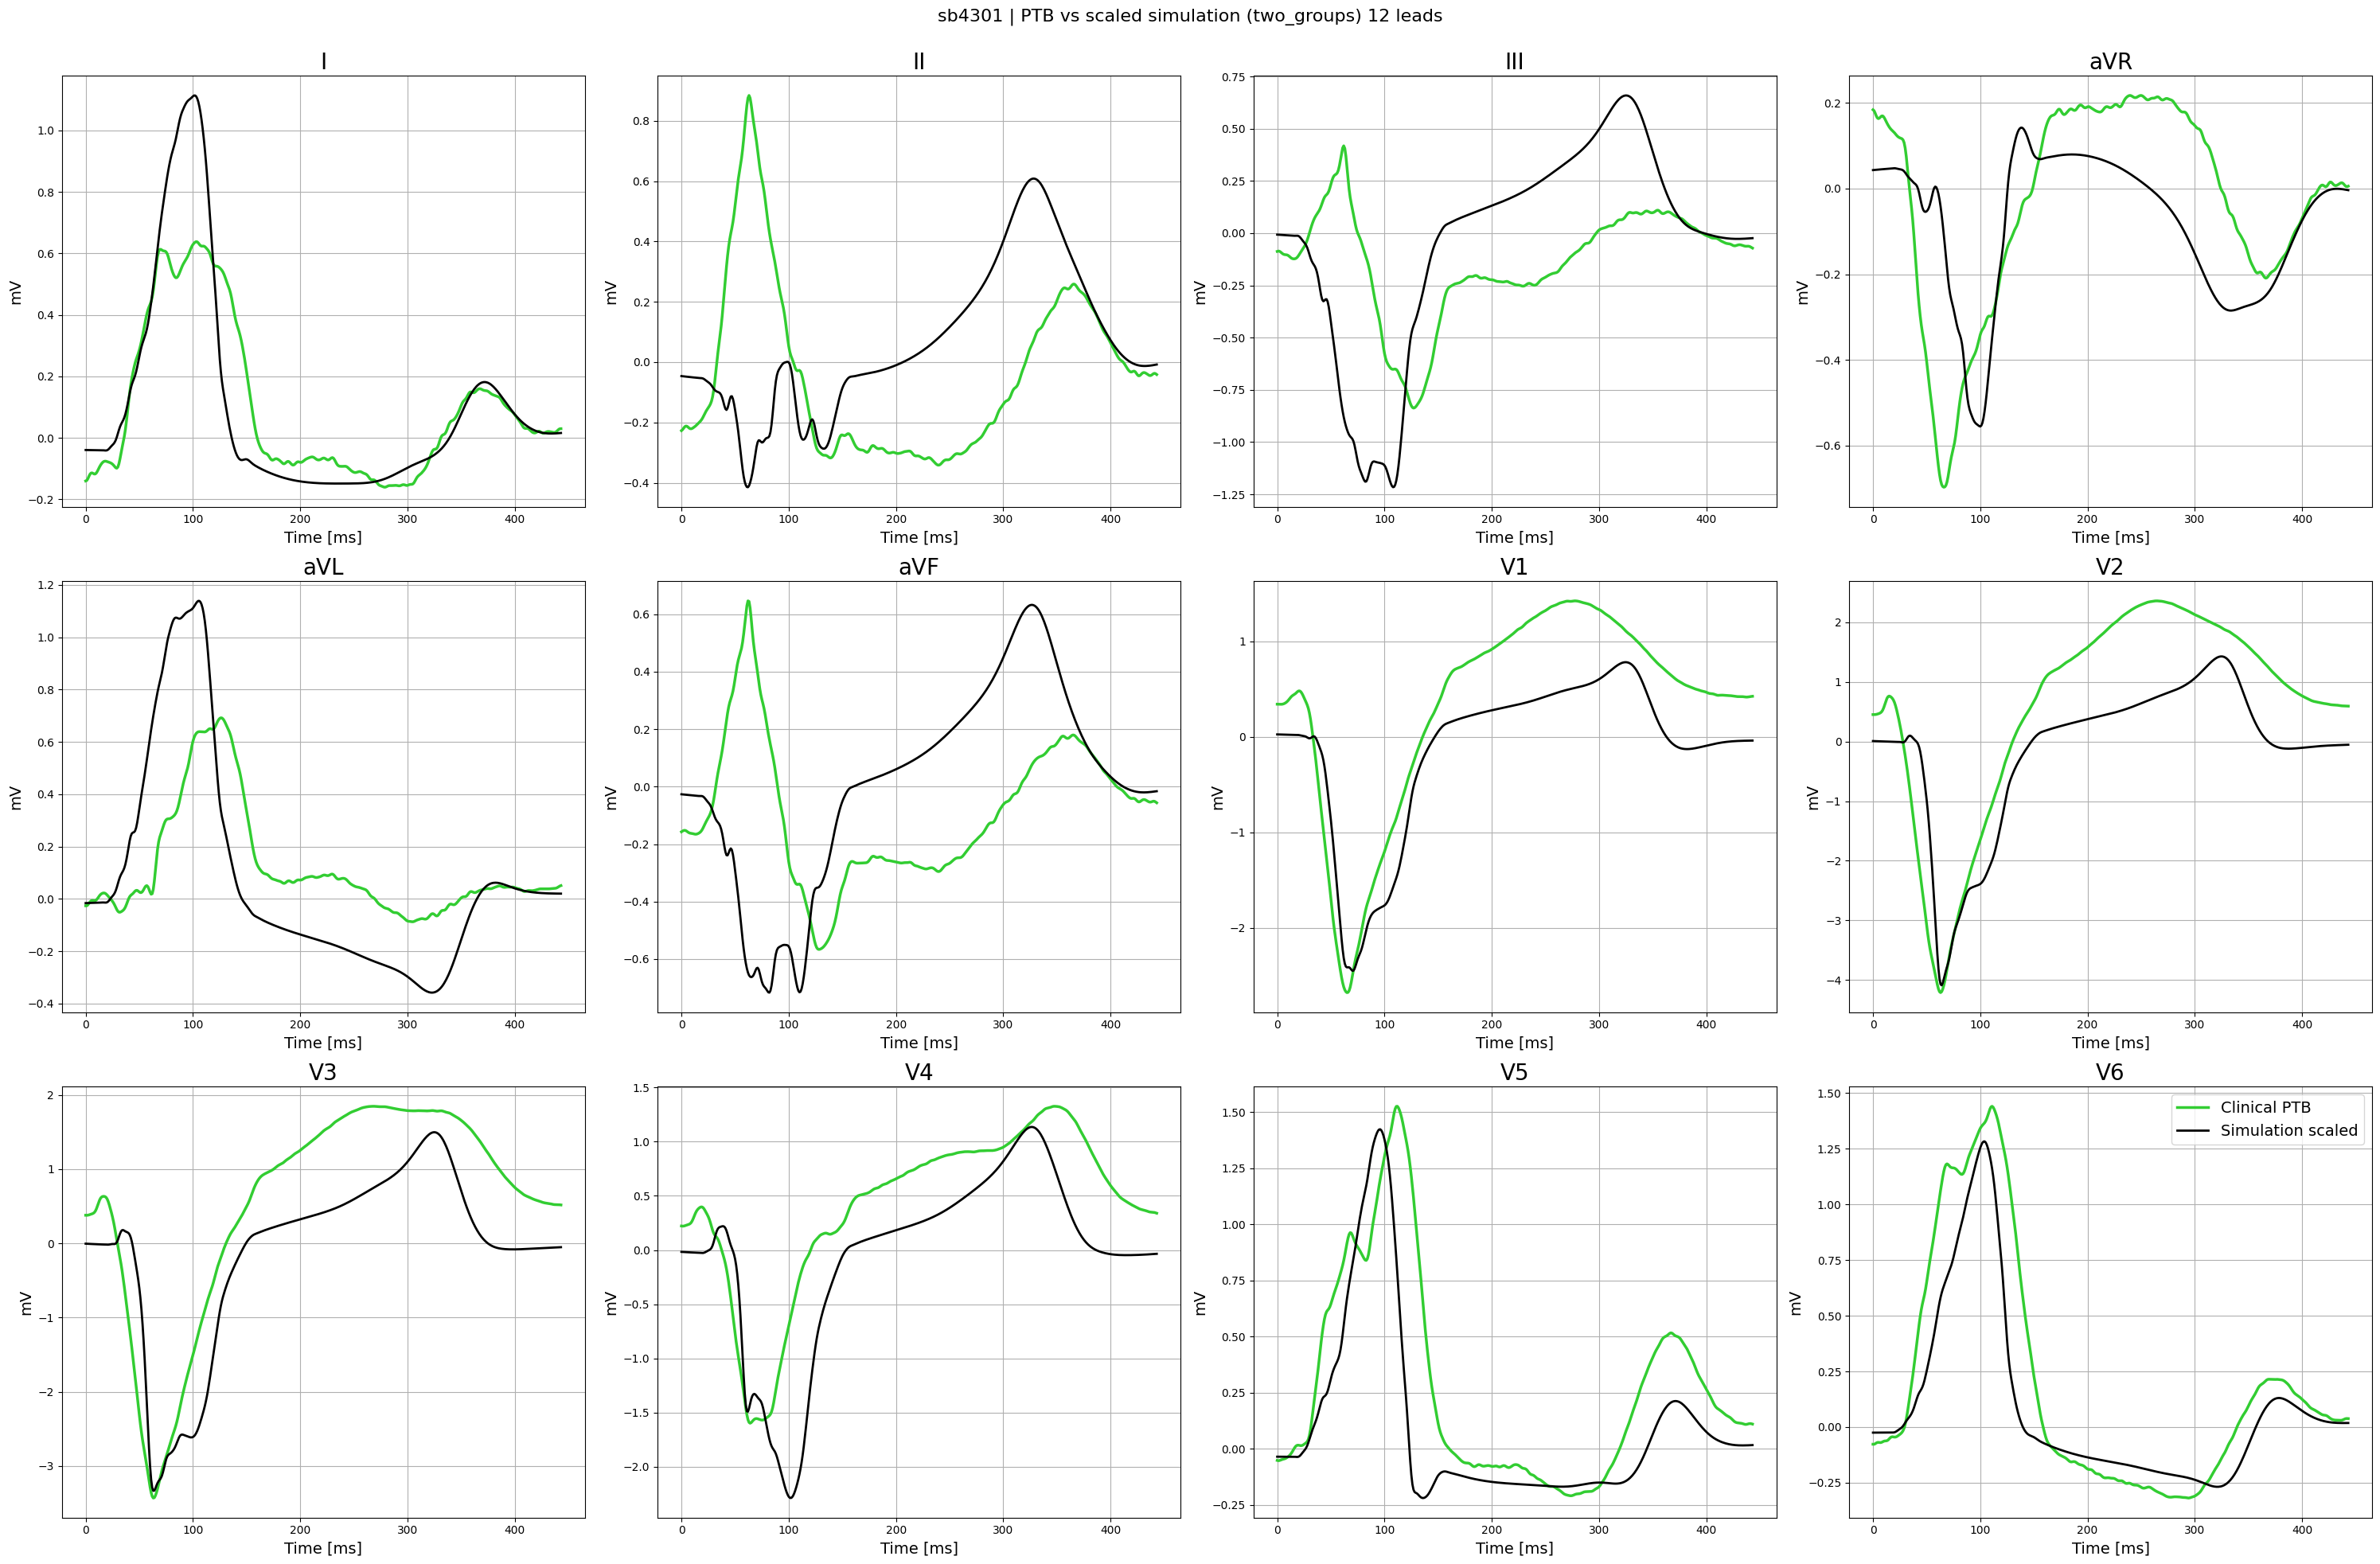

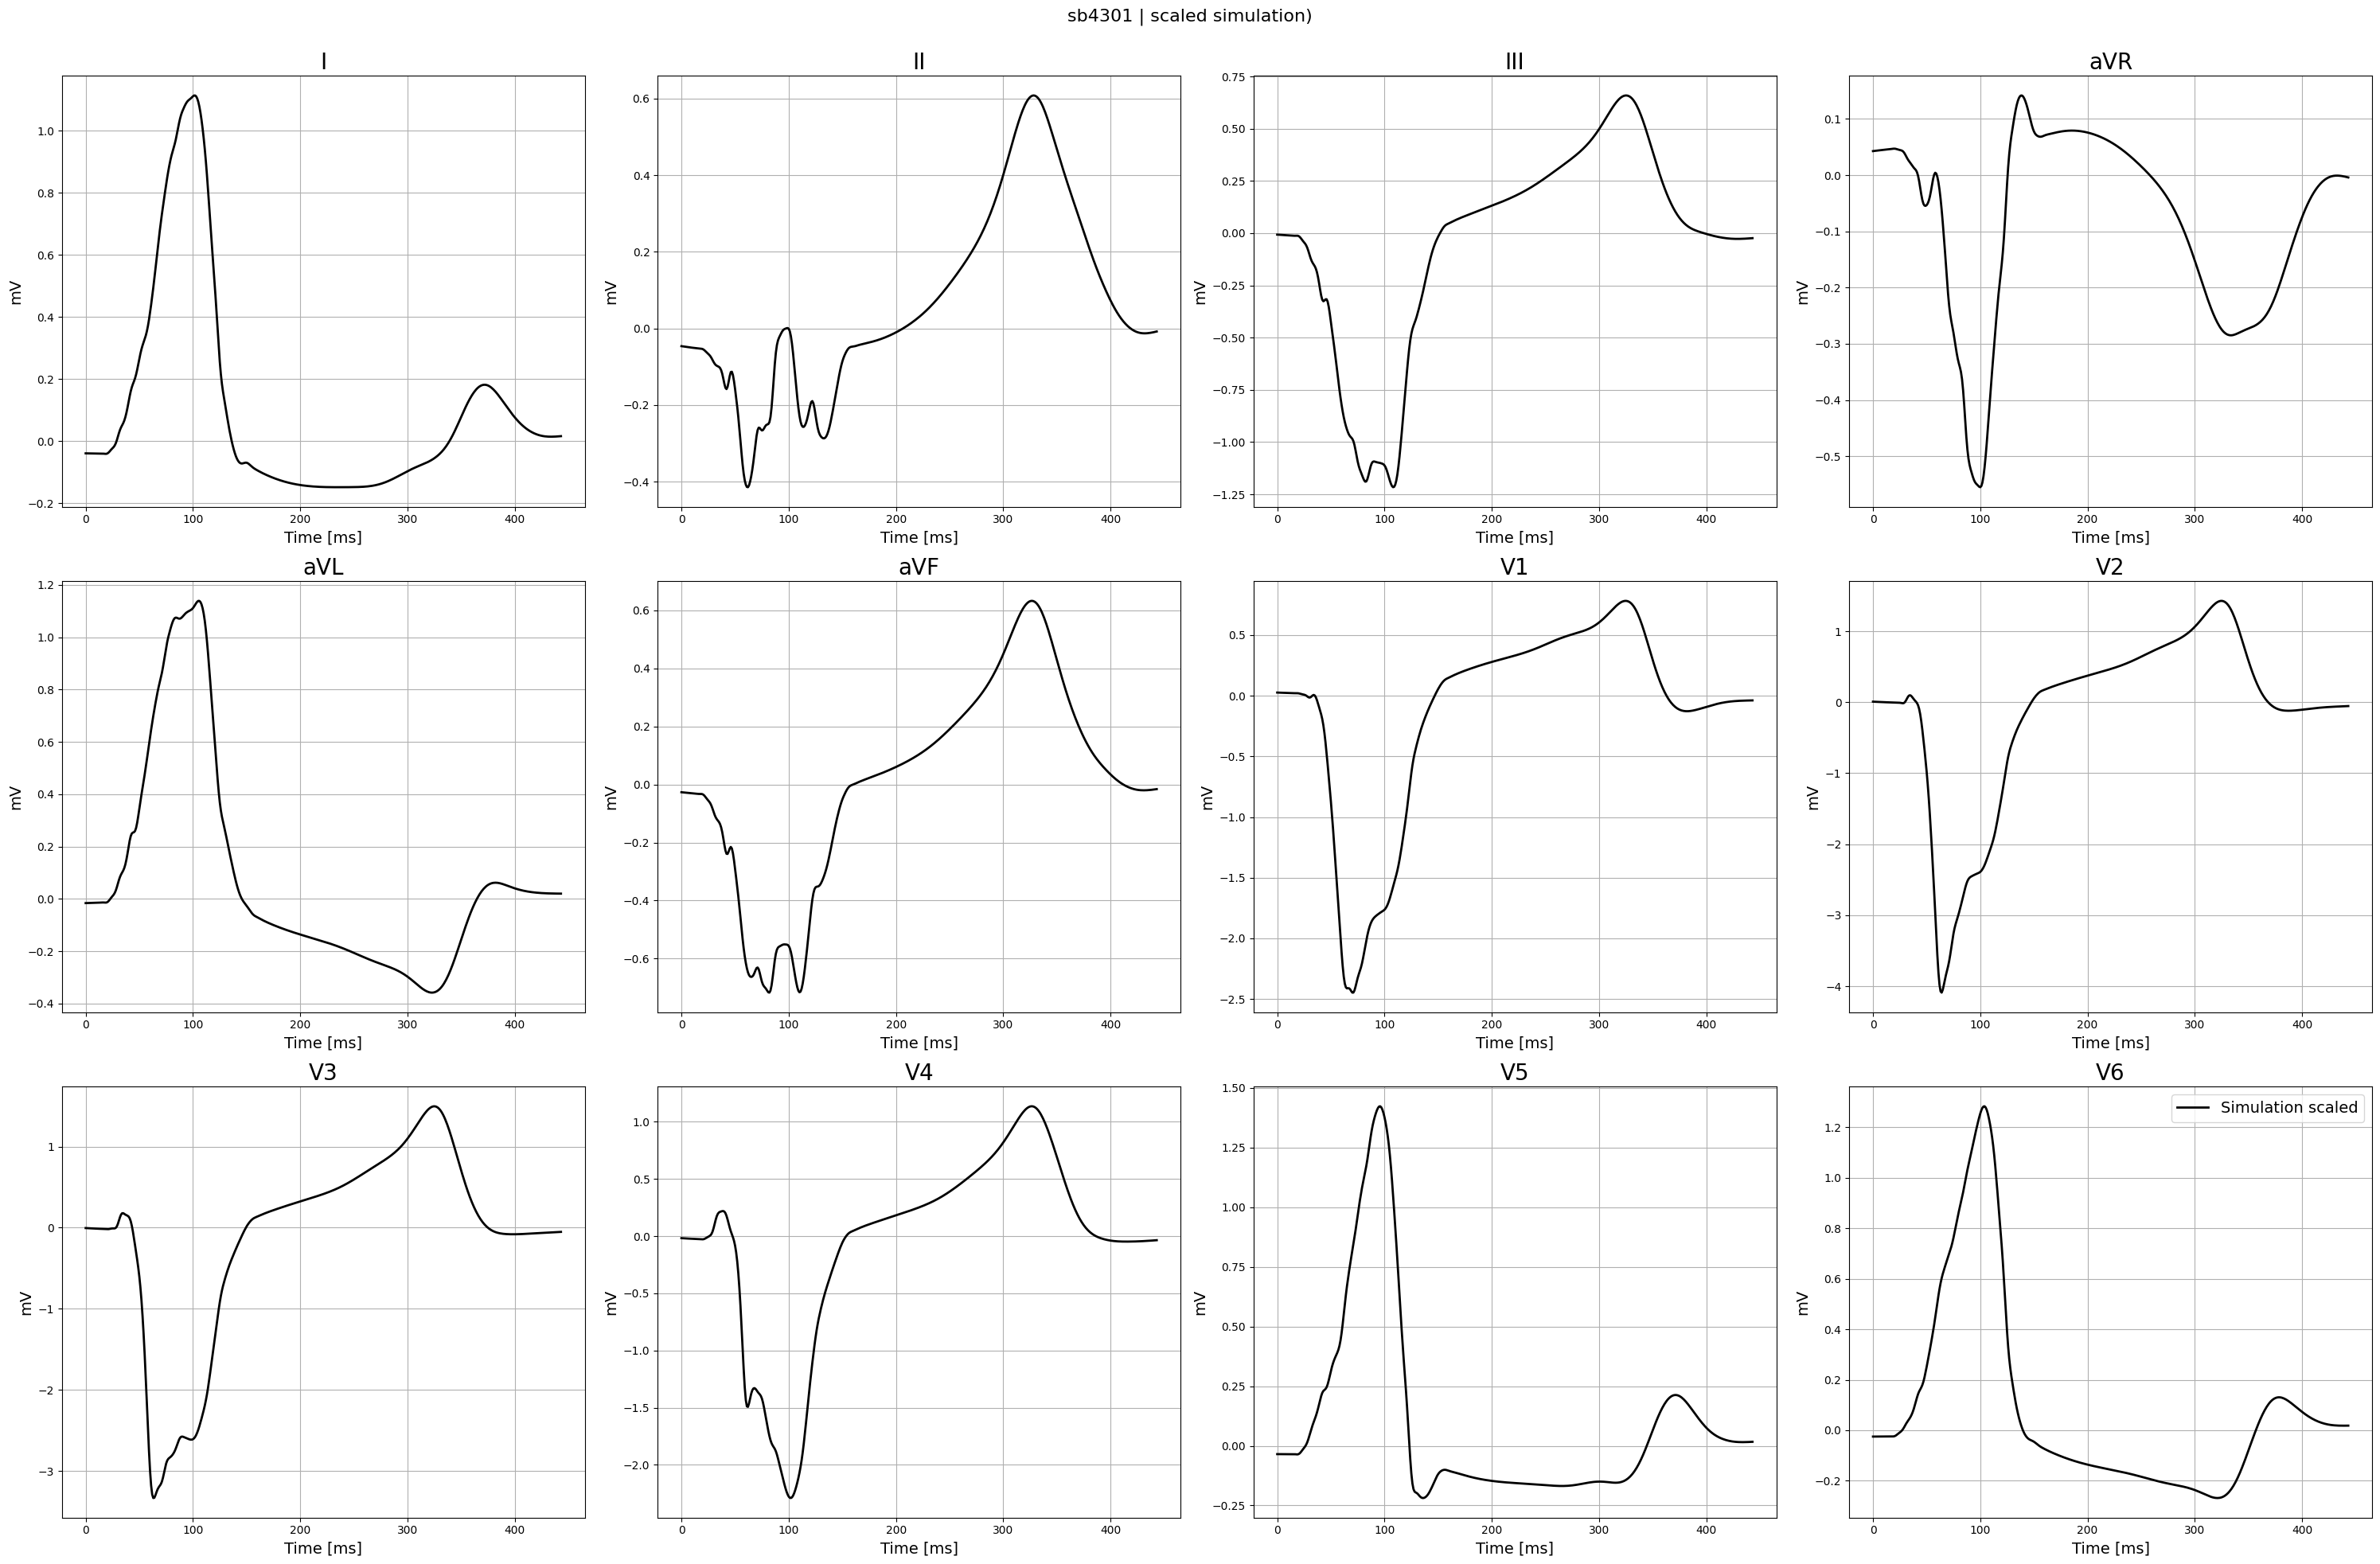

Saved clinical beat CSV: ./sb4301/test_mono_torord_sb4301_LBBB_CVcampsv2_fast4x_grad10abtm_purkinje300_prep0/patient208_reference_ptb_clinical_beat.csv
Saved scaled simulated ECG CSV: ./sb4301/test_mono_torord_sb4301_LBBB_CVcampsv2_fast4x_grad10abtm_purkinje300_prep0/sb4301_scaled_simulated_ecg.csv


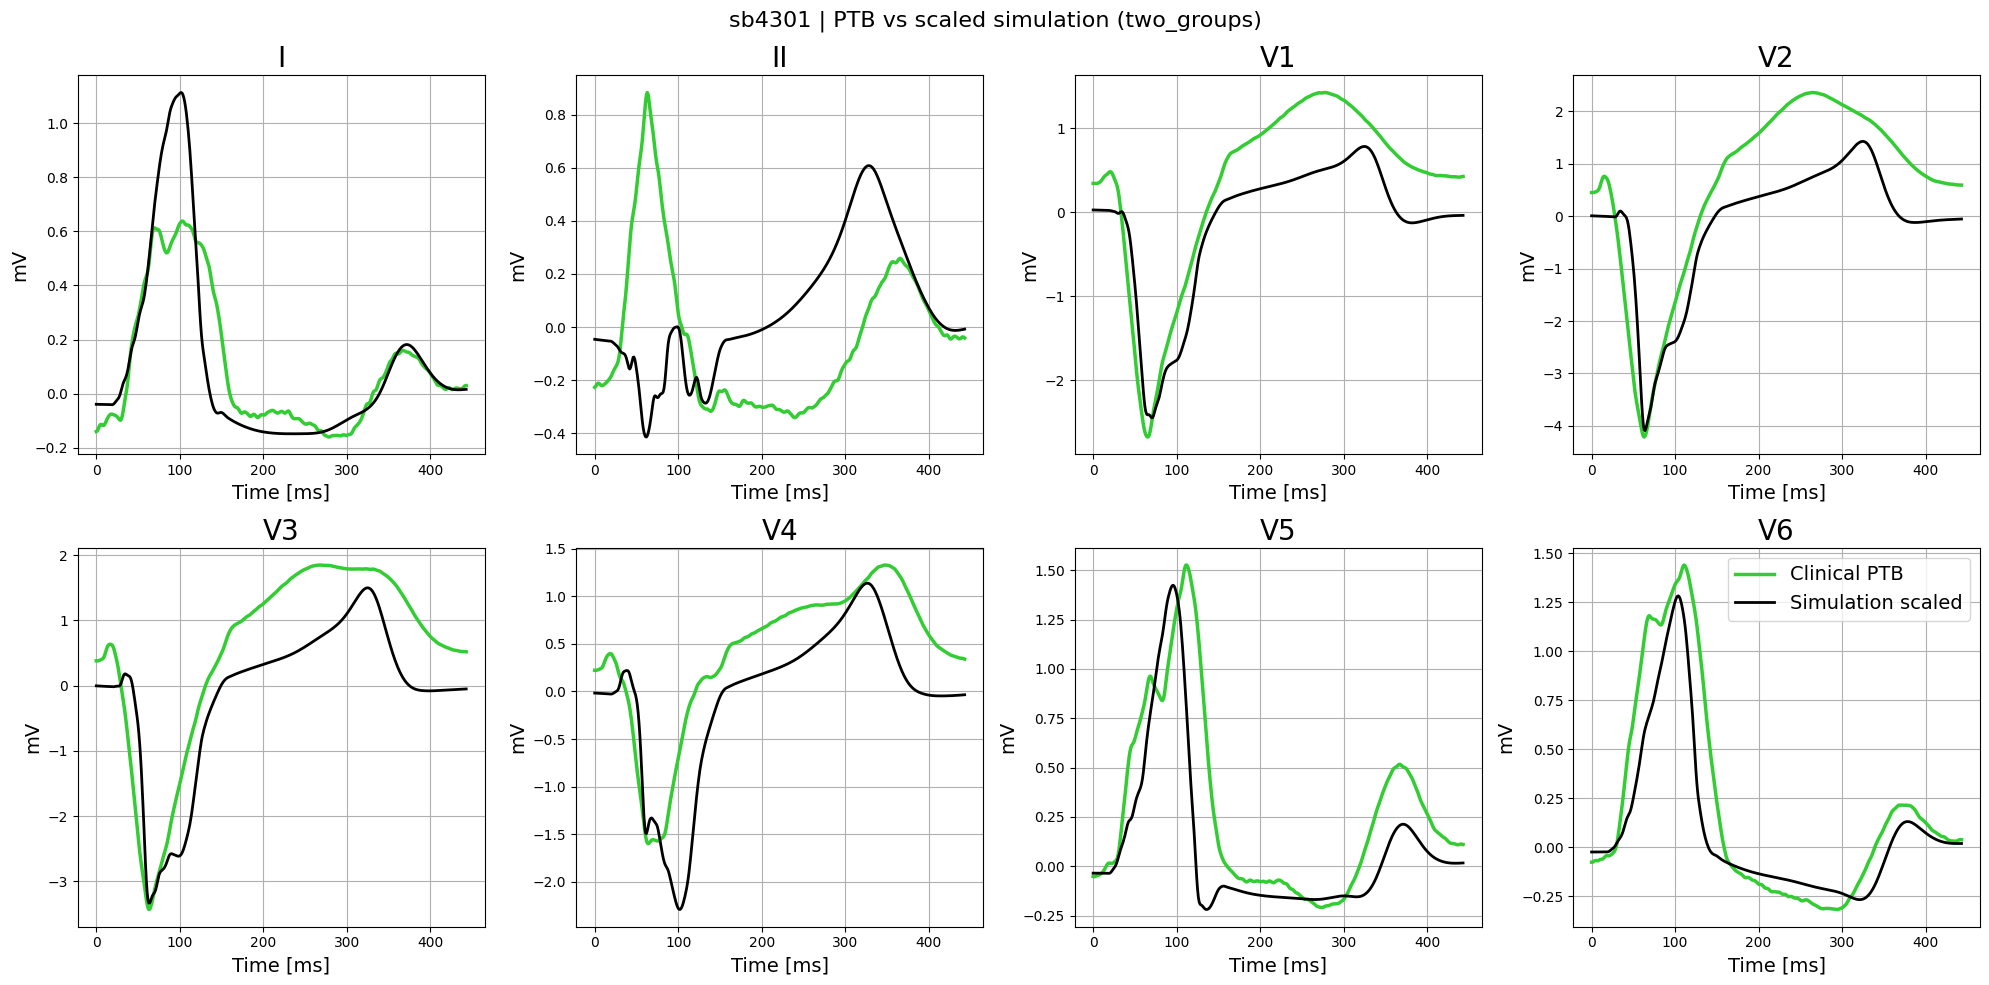

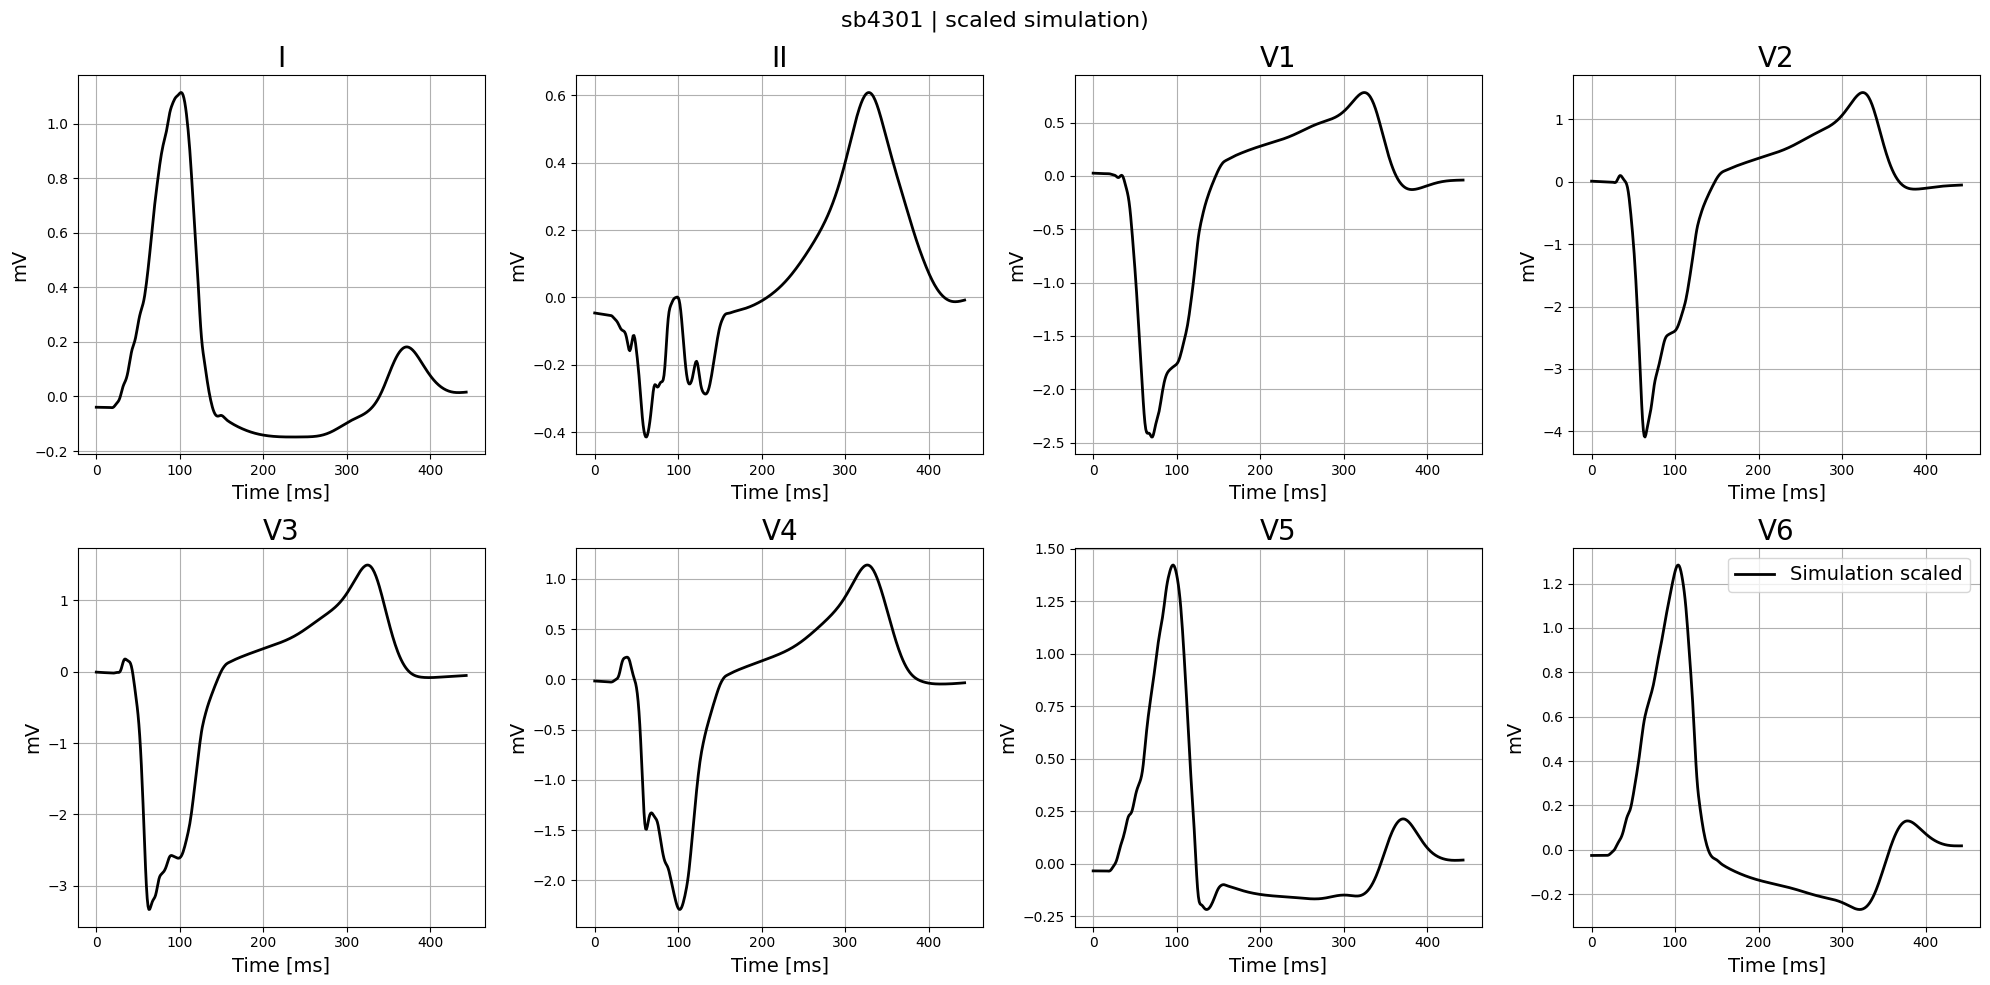

In [13]:
#preprocessing reference PTB ECG
reference_ecg_12_full = preprocess_ecg_without_normalise(
    original_ecg=reference_ecg_12_full,
    filtering=filtering,
    zero_align=zero_align,
    frequency=reference_fs,
    high_freq_cut=high_freq_cut,
    low_freq_cut=low_freq_cut,
)
#preprocessing simulated pseudo ECG
simulated_ecgs_12 = preprocess_ecg_without_normalise(
    original_ecg=simulated_ecgs_12leads,
    filtering=filtering,
    zero_align=zero_align,
    frequency=sim_freq,
    high_freq_cut=high_freq_cut,
    low_freq_cut=low_freq_cut,
)
#Select from PTB ECG a central more stable beat
reference_beat, reference_t_ms, reference_qrs_anchor, central_peak, all_peaks = select_central_ptb_beat(
    reference_ecg_12_full,
    fs=reference_fs,
    target_len_ms=ptb_target_len_ms,
    qrs_pre_ms=ptb_qrs_pre_ms,
)
print(f'Numero di picchi R trovati nel PTB: {len(all_peaks)}')
print(f'Picco centrale selezionato al campione: {central_peak}')
print(f'Beat PTB estratto shape: {reference_beat.shape}')
if abs(reference_fs - sim_freq) > 1e-9:
    reference_beat = resample_ecg(reference_beat, original_fs=reference_fs, target_fs=sim_freq)
    reference_t_ms = np.arange(reference_beat.shape[1]) * 1000.0 / sim_freq
    reference_qrs_anchor = int(round(reference_qrs_anchor * sim_freq / reference_fs))
    reference_fs = sim_freq

n = min(reference_beat.shape[1], simulated_ecgs_12.shape[1])
reference_beat = reference_beat[:, :n]
reference_t_ms = reference_t_ms[:n]
simulated_ecgs_12 = simulated_ecgs_12[:, :n]
simulated_t_ms = simulated_t_ms[:n]
#align QRS peaks between clinical and simulated
sim_qrs_anchor = np.argmax(np.mean(np.abs(simulated_ecgs_12), axis=0))
reference_beat, reference_t_ms, simulated_ecgs_12, simulated_t_ms = align_qrs_anchor(
    reference_beat,
    reference_t_ms,
    reference_qrs_anchor,
    simulated_ecgs_12,
    simulated_t_ms,
    sim_qrs_anchor,
    fs=sim_freq,
)
#scale simulated ECG amplitude to clinical using scaling mode defined above
scaled_simulated_ecgs_12, scale_factors_12, ref_amp_12, sim_amp_12 = scale_simulated_to_reference(
    reference_ecg=reference_beat,
    simulated_ecg=simulated_ecgs_12,
    fs=sim_freq,
    qrs_onset_idx=min(int(sim_qrs_anchor), reference_beat.shape[1] - 1),
    qrs_window_ms=qrs_window_ms,
    mode=scaling_mode,
)

print_scaling_report(scale_factors_12, ref_amp_12, sim_amp_12, scaling_mode, LEAD_NAMES_12)

# Save and plot 12 leads
clinical_12_csv = os.path.join(sim_folder, ptb_casename + '_reference_ptb_clinical_beat_12leads.csv')
scaled_12_csv = os.path.join(sim_folder, casename + '_scaled_simulated_ecg_12leads.csv')
out_12_png = os.path.join(sim_folder, f'{casename}_scaled_to_{ptb_casename}_{scaling_mode}_12leads.png')

save_ecg_csv(clinical_12_csv, reference_t_ms, reference_beat, LEAD_NAMES_12)
save_ecg_csv_per_row(scaled_12_csv, simulated_t_ms, scaled_simulated_ecgs_12, LEAD_NAMES_12)
save_ecg_csv_per_row(clinical_12_csv, reference_t_ms, reference_beat, LEAD_NAMES_12)

print(f'Saved clinical beat 12 leads CSV: {clinical_12_csv}')
print(f'Saved scaled simulated ECG 12 leads CSV: {scaled_12_csv}')
visualise_ecgs(
    reference_ecg=reference_beat,
    simulated_ecgs=scaled_simulated_ecgs_12,
    simulated_t_ms=simulated_t_ms,
    ref_t_ms=reference_t_ms,
    lead_names=LEAD_NAMES_12,
    casename=f'{casename} | PTB vs scaled simulation ({scaling_mode}) 12 leads',
    ylim=None,
    out_png=out_12_png,
)
out_12_png = os.path.join(sim_folder, f'{casename}_scaled_only_12leads.png')
visualise_ecgs(
    reference_ecg=None,
    simulated_ecgs=scaled_simulated_ecgs_12,
    simulated_t_ms=simulated_t_ms,
    ref_t_ms=None,
    lead_names=LEAD_NAMES_12,
    casename=f'{casename} | scaled simulation)',
    ylim=None,
    out_png=out_12_png,
)

# Extract and save 8 leads
indices_8_leads = [LEAD_NAMES_12.index(l) for l in LEAD_NAMES_8]
reference_beat_8 = reference_beat[indices_8_leads, :]
scaled_simulated_ecgs_8 = scaled_simulated_ecgs_12[indices_8_leads, :]

clinical_csv = os.path.join(sim_folder, ptb_casename + '_reference_ptb_clinical_beat.csv')
scaled_csv = os.path.join(sim_folder, casename + '_scaled_simulated_ecg.csv')
out_png = os.path.join(sim_folder, f'{casename}_scaled_to_{ptb_casename}_{scaling_mode}.png')

save_ecg_csv(clinical_csv, reference_t_ms, reference_beat_8, LEAD_NAMES_8)
save_ecg_csv_per_row(scaled_csv, simulated_t_ms, scaled_simulated_ecgs_8, LEAD_NAMES_8)
save_ecg_csv_per_row(clinical_csv, reference_t_ms, reference_beat_8, LEAD_NAMES_8)

print(f'Saved clinical beat CSV: {clinical_csv}')
print(f'Saved scaled simulated ECG CSV: {scaled_csv}')
#save comparison between simulated scaled ECG vs PTB ECG
visualise_ecgs(
    reference_ecg=reference_beat_8,
    simulated_ecgs=scaled_simulated_ecgs_8,
    simulated_t_ms=simulated_t_ms,
    ref_t_ms=reference_t_ms,
    lead_names=LEAD_NAMES_8,
    casename=f'{casename} | PTB vs scaled simulation ({scaling_mode})',
    ylim=None,
    out_png=out_png,
)
#save only simulated scaled ECG
out_png = os.path.join(sim_folder, f'{casename}_scaled_only.png')
visualise_ecgs(
    reference_ecg=None,
    simulated_ecgs=scaled_simulated_ecgs_8,
    simulated_t_ms=simulated_t_ms,
    ref_t_ms=None,
    lead_names=LEAD_NAMES_8,
    casename=f'{casename} | scaled simulation)',
    ylim=None,
    out_png=out_png,
)